# Análisis del Dataset SFT (`sft.jsonl`)

In [1]:
import json
import random
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_path(candidates):
    for p in candidates:
        if Path(p).exists():
            return Path(p)
    return None

SFT_PATH   = find_path(["outputs/sft.jsonl", "../outputs/sft.jsonl", "/content/drive/MyDrive/GenAI/sft.jsonl"])
TRAIN_PATH = find_path(["dataset/train.jsonl", "../dataset/train.jsonl", "/content/drive/MyDrive/GenAI/train.jsonl"])
EVAL_PATH  = find_path(["dataset/eval.jsonl", "../dataset/eval.jsonl", "/content/drive/MyDrive/GenAI/eval.jsonl"])
TEST_PATH  = find_path(["dataset/test.jsonl", "../dataset/test.jsonl", "/content/drive/MyDrive/GenAI/test.jsonl"])
DPO_PATH   = find_path(["outputs/dpo.jsonl", "../outputs/dpo.jsonl", "/content/drive/MyDrive/GenAI/dpo.jsonl"])

SFT_PATH, TRAIN_PATH, DPO_PATH, TEST_PATH

In [2]:
def load_jsonl(p):
    if p is None or not p.exists():
        return []
    with open(p, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

sft_rows    = load_jsonl(SFT_PATH)
train_tasks = {r["id"]: r for r in load_jsonl(TRAIN_PATH)}
eval_tasks  = {r["id"]: r for r in load_jsonl(EVAL_PATH)}
test_tasks  = {r["id"]: r for r in load_jsonl(TEST_PATH)}
dpo_rows    = load_jsonl(DPO_PATH)

sft_ids = {r["task_id"] for r in sft_rows}
print(f"sft.jsonl: {len(sft_rows)} trazas | {len(sft_ids)} task_id únicos")
print(f"train.jsonl: {len(train_tasks)} | eval.jsonl: {len(eval_tasks)} | test.jsonl: {len(test_tasks)} | dpo.jsonl: {len(dpo_rows)}")

sft.jsonl: 2991 trazas | 1156 task_id únicos
train.jsonl: 1565 | eval.jsonl: 333 | test.jsonl: 602 | dpo.jsonl: 1854


## Chequeo rápido de integridad

In [3]:
leak_eval = sft_ids & set(eval_tasks)
leak_test = sft_ids & set(test_tasks)
asst_result = [
    (i, r["task_id"])
    for i, r in enumerate(sft_rows)
    if any("<result>" in m["content"].lower() for m in r["messages"] if m["role"] == "assistant")
]
format_err_turns = [
    (i, r["task_id"])
    for i, r in enumerate(sft_rows)
    if any(
        ("Etiquetas mal formadas" in m["content"] or "No se detectó bloque sql" in m["content"])
        for m in r["messages"] if m["role"] == "user"
    )
]
missing_sql = sum(1 for r in sft_rows if "<sql>" not in "\n".join(m["content"].lower() for m in r["messages"] if m["role"] == "assistant"))
missing_ans = sum(1 for r in sft_rows if "<answer>" not in "\n".join(m["content"].lower() for m in r["messages"] if m["role"] == "assistant"))

display(pd.DataFrame([
    ("Fuga a eval.jsonl", len(leak_eval)),
    ("Fuga a test.jsonl", len(leak_test)),
    ("Sin <sql>", missing_sql),
    ("Sin <answer>", missing_ans),
    ("Turnos assistant con <result>", len(asst_result)),
    ("Trazas con turno de error de formato", len(format_err_turns)),
], columns=["Chequeo", "Cantidad"]))

if format_err_turns:
    print("Trazas con error de formato intermedio:", format_err_turns)

                             Chequeo  Cantidad
                   Fuga a eval.jsonl         0
                   Fuga a test.jsonl         0
                           Sin <sql>         0
                        Sin <answer>         0
       Turnos assistant con <result>         0
Trazas con turno de error de formato         0


Chequeo,Cantidad
Fuga a eval.jsonl,0
Fuga a test.jsonl,0
Sin <sql>,0
Sin <answer>,0
Turnos assistant con <result>,0
Trazas con turno de error de formato,0


## Proporciones por dificultad

difficulty  train (%)  sft_rows  sft (%)  sft_cobertura (%)  trazas/tarea  dpo (%)  test (%)
      easy       24.5       793     26.5               99.5          2.08     21.3      30.6
    medium       26.4      1294     43.3               91.8          3.41     36.7      32.7
      hard       29.8       663     22.2               59.4          2.39     29.4      22.4
    expert       19.3       241      8.1               39.1          2.04     12.6      14.3


difficulty,train (%),sft_rows,sft (%),sft_cobertura (%),trazas/tarea,dpo (%),test (%)
easy,24.5,793,26.5,99.5,2.08,21.3,30.6
medium,26.4,1294,43.3,91.8,3.41,36.7,32.7
hard,29.8,663,22.2,59.4,2.39,29.4,22.4
expert,19.3,241,8.1,39.1,2.04,12.6,14.3


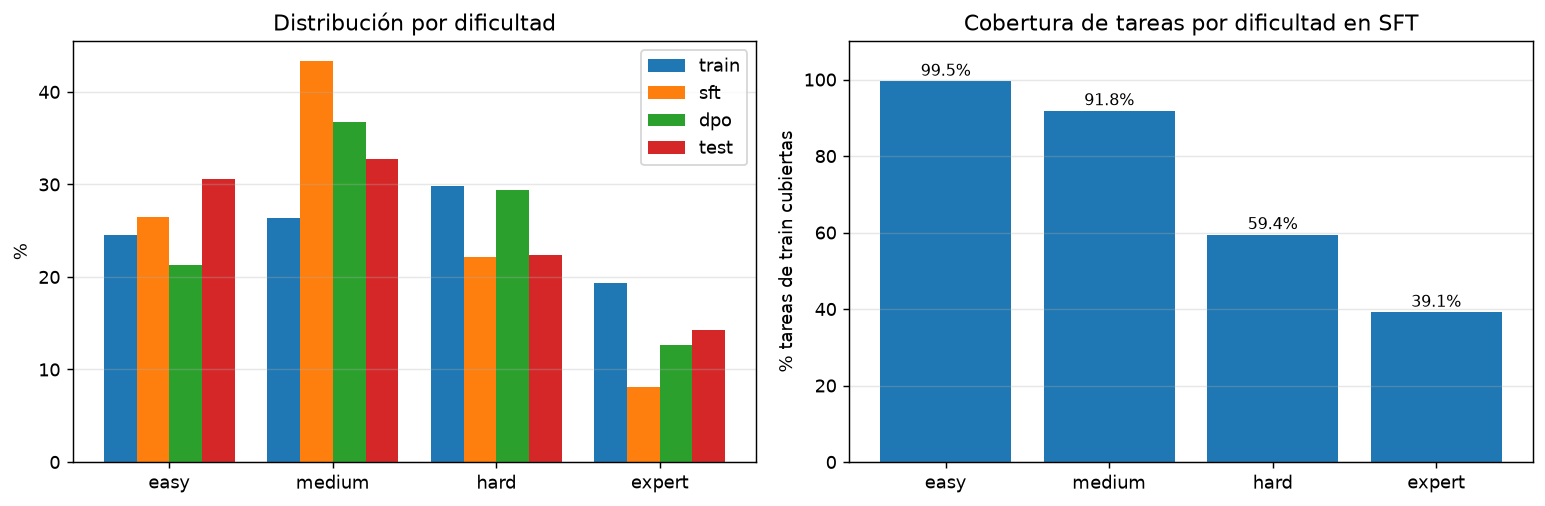

In [4]:
DIFFS = ["easy", "medium", "hard", "expert"]

train_diff = Counter(t["difficulty"] for t in train_tasks.values())
sft_diff   = Counter(train_tasks[r["task_id"]]["difficulty"] for r in sft_rows if r["task_id"] in train_tasks)
sft_u_diff = Counter(train_tasks[tid]["difficulty"] for tid in sft_ids if tid in train_tasks)
dpo_diff   = Counter(r["difficulty"] for r in dpo_rows)
test_diff  = Counter(t["difficulty"] for t in test_tasks.values())

diff_df = pd.DataFrame([
    {
        "difficulty": d,
        "train (%)": round(100 * train_diff[d] / len(train_tasks), 1),
        "sft_rows": sft_diff[d],
        "sft (%)": round(100 * sft_diff[d] / len(sft_rows), 1),
        "sft_cobertura (%)": round(100 * sft_u_diff[d] / train_diff[d], 1),
        "trazas/tarea": round(sft_diff[d] / max(sft_u_diff[d], 1), 2),
        "dpo (%)": round(100 * dpo_diff[d] / len(dpo_rows), 1) if dpo_rows else np.nan,
        "test (%)": round(100 * test_diff[d] / len(test_tasks), 1) if test_tasks else np.nan,
    }
    for d in DIFFS
])
display(diff_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(DIFFS))
w = 0.2
axes[0].bar(x - 1.5*w, diff_df["train (%)"], width=w, label="train")
axes[0].bar(x - 0.5*w, diff_df["sft (%)"], width=w, label="sft")
if dpo_rows:
    axes[0].bar(x + 0.5*w, diff_df["dpo (%)"], width=w, label="dpo")
if test_tasks:
    axes[0].bar(x + 1.5*w, diff_df["test (%)"], width=w, label="test")
axes[0].set_xticks(x)
axes[0].set_xticklabels(DIFFS)
axes[0].set_ylabel("%")
axes[0].set_title("Distribución por dificultad")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(DIFFS, diff_df["sft_cobertura (%)"])
for i, v in enumerate(diff_df["sft_cobertura (%)"]):
    axes[1].text(i, v + 1.5, f"{v}%", ha="center", fontsize=9)
axes[1].set_ylim(0, 110)
axes[1].set_ylabel("% tareas de train cubiertas")
axes[1].set_title("Cobertura de tareas por dificultad en SFT")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Tipos de respuesta, turnos y multiplicidad

Con <think>: 65 (2.2%) | Con recuperación de ERROR: 384 (12.8%)


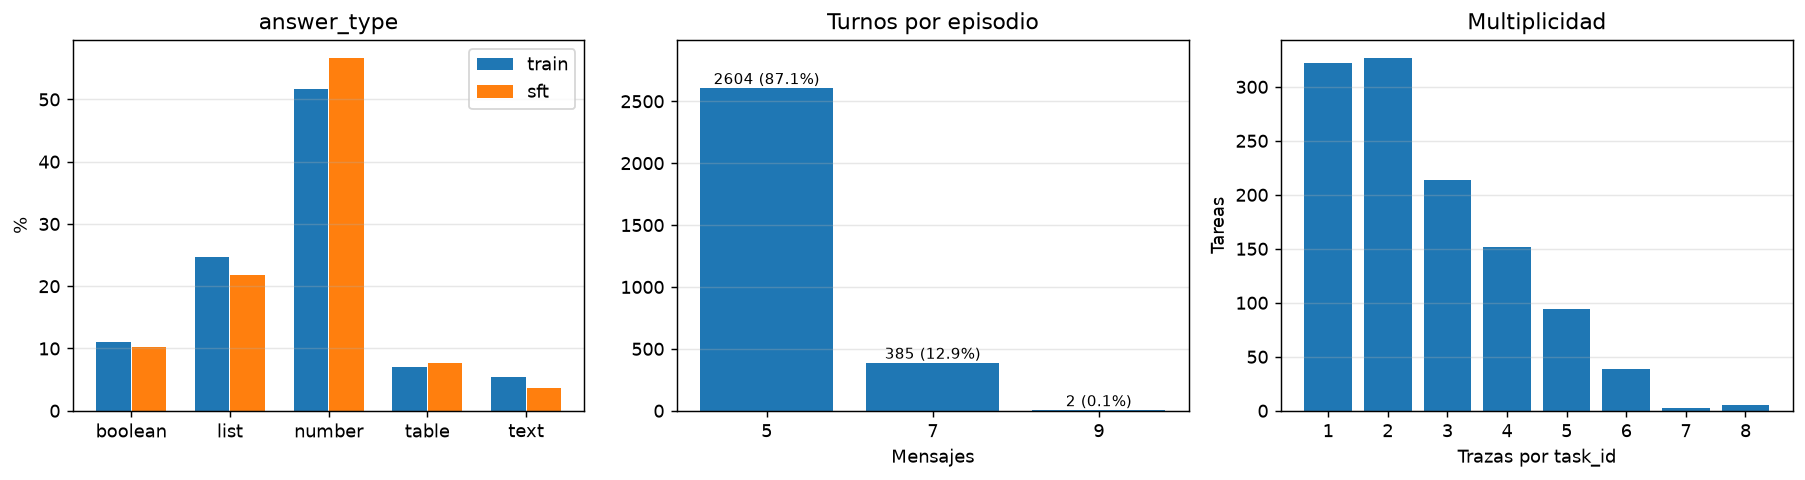

In [5]:
msg_counts = Counter(len(r["messages"]) for r in sft_rows)
per_task   = Counter(r["task_id"] for r in sft_rows)
mult_dist  = Counter(per_task.values())
has_think  = sum(1 for r in sft_rows if any("<think>" in m["content"] for m in r["messages"] if m["role"] == "assistant"))
has_err    = sum(1 for r in sft_rows if any("ERROR:" in m["content"] for m in r["messages"] if m["role"] == "user"))

print(f"Con <think>: {has_think} ({100*has_think/len(sft_rows):.1f}%) | Con recuperación de ERROR: {has_err} ({100*has_err/len(sft_rows):.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

at_keys = sorted({t["answer_type"] for t in train_tasks.values()})
tr_at = Counter(t["answer_type"] for t in train_tasks.values())
sft_at = Counter(train_tasks[r["task_id"]]["answer_type"] for r in sft_rows if r["task_id"] in train_tasks)
x = np.arange(len(at_keys))
axes[0].bar(x - 0.18, [100*tr_at[k]/len(train_tasks) for k in at_keys], width=0.35, label="train")
axes[0].bar(x + 0.18, [100*sft_at[k]/len(sft_rows) for k in at_keys], width=0.35, label="sft")
axes[0].set_xticks(x)
axes[0].set_xticklabels(at_keys)
axes[0].set_ylabel("%")
axes[0].set_title("answer_type")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

tk = sorted(msg_counts)
axes[1].bar([str(k) for k in tk], [msg_counts[k] for k in tk])
for i, k in enumerate(tk):
    axes[1].text(i, msg_counts[k] + 35, f"{msg_counts[k]} ({100*msg_counts[k]/len(sft_rows):.1f}%)", ha="center", fontsize=8.5)
axes[1].set_ylim(0, max(msg_counts.values()) * 1.15)
axes[1].set_xlabel("Mensajes")
axes[1].set_title("Turnos por episodio")
axes[1].grid(axis="y", alpha=0.3)

mk = sorted(mult_dist)
axes[2].bar([str(k) for k in mk], [mult_dist[k] for k in mk])
axes[2].set_xlabel("Trazas por task_id")
axes[2].set_ylabel("Tareas")
axes[2].set_title("Multiplicidad")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Plantillas (`template_id`)

Plantillas en train: 53 | Cubiertas en SFT: 48 | Sin cobertura: 5
                                     template_id difficulty  train_tasks
count_admitted_room_patients_prescribed_category     expert           22
  doctors_more_appointments_than_supervisor_year     expert           12
            patients_spend_above_factor_city_avg     expert           11
          top_k_departments_admission_spend_room       hard            8
                  top_k_patients_total_stay_city     expert           25


template_id,difficulty,train_tasks
count_admitted_room_patients_prescribed_category,expert,22
doctors_more_appointments_than_supervisor_year,expert,12
patients_spend_above_factor_city_avg,expert,11
top_k_departments_admission_spend_room,hard,8
top_k_patients_total_stay_city,expert,25


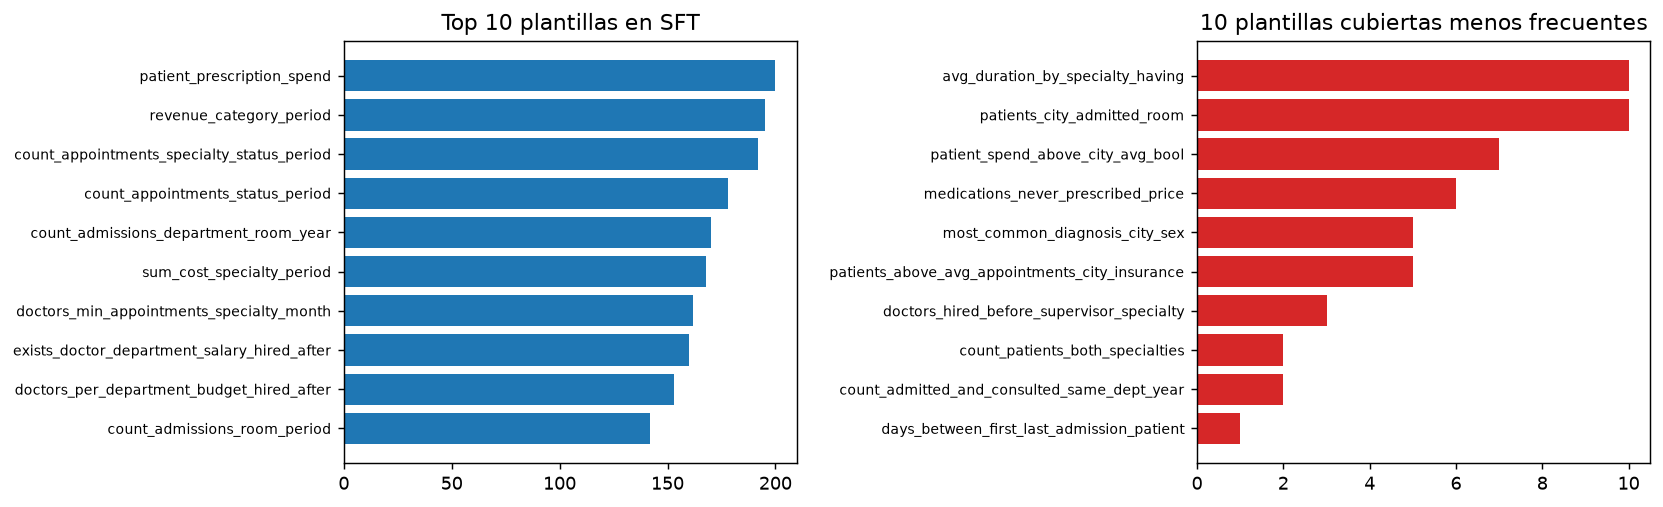

In [6]:
train_tpls = Counter(t["template_id"] for t in train_tasks.values())
sft_tpls   = Counter(train_tasks[r["task_id"]]["template_id"] for r in sft_rows if r["task_id"] in train_tasks)
tpl_diff   = {t["template_id"]: t["difficulty"] for t in train_tasks.values()}

zero_tpls = sorted([tpl for tpl in train_tpls if sft_tpls[tpl] == 0])
print(f"Plantillas en train: {len(train_tpls)} | Cubiertas en SFT: {len(sft_tpls)} | Sin cobertura: {len(zero_tpls)}")
display(pd.DataFrame([{"template_id": t, "difficulty": tpl_diff[t], "train_tasks": train_tpls[t]} for t in zero_tpls]))

tpl_df = pd.DataFrame([
    {"template_id": tpl, "difficulty": tpl_diff[tpl], "sft_rows": sft_tpls[tpl]}
    for tpl in train_tpls
]).sort_values("sft_rows", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top10 = tpl_df.head(10).iloc[::-1]
bot10 = tpl_df[tpl_df["sft_rows"] > 0].tail(10).iloc[::-1]
axes[0].barh(top10["template_id"], top10["sft_rows"])
axes[0].set_title("Top 10 plantillas en SFT")
axes[0].tick_params(axis="y", labelsize=8)
axes[1].barh(bot10["template_id"], bot10["sft_rows"], color="tab:red")
axes[1].set_title("10 plantillas cubiertas menos frecuentes")
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

## Largos de secuencia y `MAX_LEN`

              Métrica    min    p50    p90    p99    max
    Total (est. toks) 2425.9 2494.5 2582.4 2658.8 3047.8
Assistant (est. toks)   32.3   78.4  140.6  201.8  617.9
 MAX_LEN  truncados  % truncado
    2048       2991      100.00
    2560        462       15.45
    2816          3        0.10
    3072          0        0.00
    3200          0        0.00


Métrica,min,p50,p90,p99,max
Total (est. toks),2425.9,2494.5,2582.4,2658.8,3047.8
Assistant (est. toks),32.3,78.4,140.6,201.8,617.9


MAX_LEN,truncados,% truncado
2048,2991,100.00
2560,462,15.45
2816,3,0.10
3072,0,0.00
3200,0,0.00


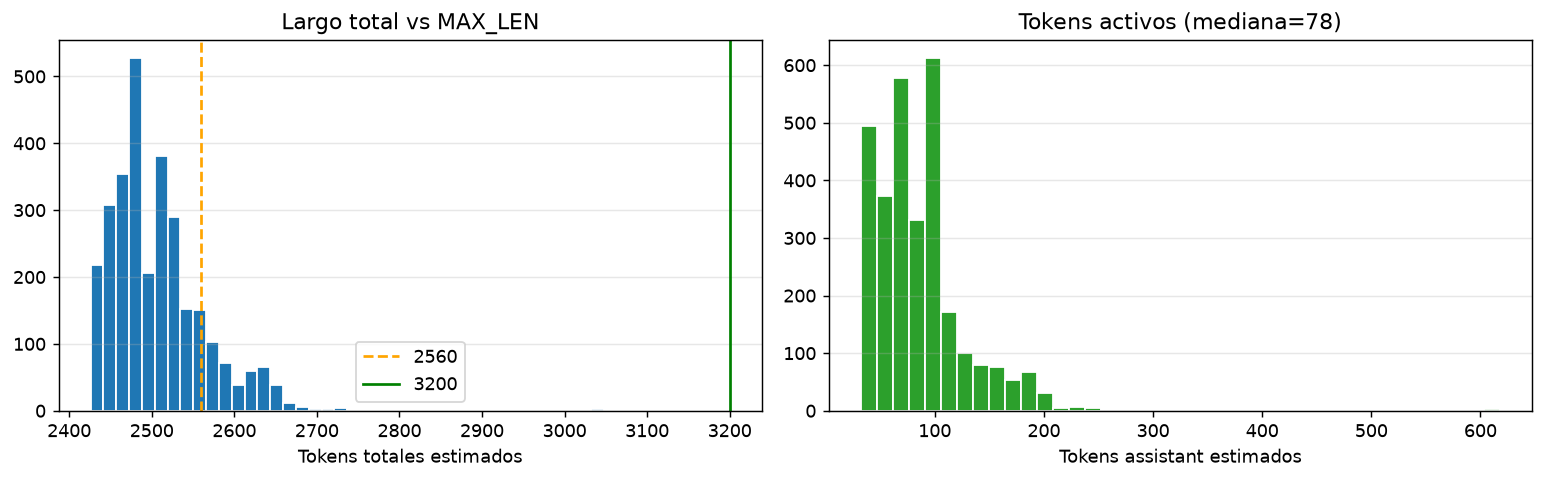

In [7]:
CHARS_PER_TOK = 3.47
est_total = np.array([sum(len(m["content"]) + 20 for m in r["messages"]) for r in sft_rows]) / CHARS_PER_TOK
est_asst  = np.array([sum(len(m["content"]) + 10 for m in r["messages"] if m["role"] == "assistant") for r in sft_rows]) / CHARS_PER_TOK

display(pd.DataFrame([
    ("Total (est. toks)", np.min(est_total), np.percentile(est_total, 50), np.percentile(est_total, 90), np.percentile(est_total, 99), np.max(est_total)),
    ("Assistant (est. toks)", np.min(est_asst), np.percentile(est_asst, 50), np.percentile(est_asst, 90), np.percentile(est_asst, 99), np.max(est_asst)),
], columns=["Métrica", "min", "p50", "p90", "p99", "max"]).round(1))

display(pd.DataFrame([
    {"MAX_LEN": ml, "truncados": int(np.sum(est_total > ml)), "% truncado": round(100 * np.mean(est_total > ml), 2)}
    for ml in [2048, 2560, 2816, 3072, 3200]
]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(est_total, bins=40, edgecolor="white")
axes[0].axvline(2560, color="orange", linestyle="--", label="2560")
axes[0].axvline(3200, color="green", linestyle="-", label="3200")
axes[0].set_xlabel("Tokens totales estimados")
axes[0].set_title("Largo total vs MAX_LEN")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

axes[1].hist(est_asst, bins=40, color="tab:green", edgecolor="white")
axes[1].set_xlabel("Tokens assistant estimados")
axes[1].set_title(f"Tokens activos (mediana={np.median(est_asst):.0f})")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Comparación de split: 95/5 vs 90/10

In [8]:
all_tids = sorted(sft_ids)
random.Random(42).shuffle(all_tids)

rows_cmp = []
for pct in [0.05, 0.10]:
    v_ids = set(all_tids[: int(len(all_tids) * pct)])
    v_rows = [r for r in sft_rows if r["task_id"] in v_ids]
    v_diff = Counter(train_tasks[r["task_id"]]["difficulty"] for r in v_rows if r["task_id"] in train_tasks)
    v_t_diff = Counter(train_tasks[tid]["difficulty"] for tid in v_ids if tid in train_tasks)
    rows_cmp.append({
        "split": f"{int((1-pct)*100)}/{int(pct*100)}",
        "train_rows": len(sft_rows) - len(v_rows),
        "val_rows": len(v_rows),
        "val_tasks": len(v_ids),
        "val_easy (t/r)": f"{v_t_diff['easy']}/{v_diff['easy']}",
        "val_medium (t/r)": f"{v_t_diff['medium']}/{v_diff['medium']}",
        "val_hard (t/r)": f"{v_t_diff['hard']}/{v_diff['hard']}",
        "val_expert (t/r)": f"{v_t_diff['expert']}/{v_diff['expert']}",
    })
display(pd.DataFrame(rows_cmp))

split  train_rows  val_rows  val_tasks val_easy (t/r) val_medium (t/r) val_hard (t/r) val_expert (t/r)
 95/5        2832       159         57          26/64            18/65           8/22              5/8
90/10        2679       312        115         48/105           36/125          20/61            11/21


split,train_rows,val_rows,val_tasks,val_easy (t/r),val_medium (t/r),val_hard (t/r),val_expert (t/r)
95/5,2832,159,57,26/64,18/65,8/22,5/8
90/10,2679,312,115,48/105,36/125,20/61,11/21
